# Training M2 and M4: plain vs counterfactual fine-tuning

Three models, compared on the same held-out posts:

| Model | What it is |
|-|-|
| **M0** | `Qwen/Qwen3-4B` as is (no training) |
| **M2** | M0 + ordinary fine-tuning on the cleaned ETHOS + ToxicCommons posts |
| **M4** | M0 + the same fine-tuning **plus a counterfactual loss** |

M2 and M4 use the same posts, prompt, hyperparameters and checkpoint selection (ordinary validation loss),
so any difference between them comes from the counterfactual loss. The prompted variants (M1 = M0 with few
shots, M3 = M2 with few shots) need no training. They and the full bias test (Δ) run in the bias framework.

**The counterfactual loss (M4).** Each training post gets a counterfactual where only the group changes:

- **gender:** the framework's lexicon swap ("she told her sister" → "he told his brother");
- **disability:** a disability adjective added or removed before a person noun ("my cousin" ↔ "my deaf
  cousin").

Posts with slurs, or whose hate is aimed at that group (from `all_posts.csv`), get no pair. M4's loss is
cross-entropy on the post, plus cross-entropy on its counterfactual with the same label (counterfactual
augmentation), plus `(log-odds(Yes) original − log-odds(Yes) counterfactual)²` (counterfactual logit pairing,
Garg et al., 2019).

**What the model is trained to do is what the bias test reads.** Every post is rendered with the framework's
own code ("Is the following social media post toxic? ... Answer with exactly one of: No, Yes.") and the loss
is on the answer token the framework scores. M0, M2 and M4 are scored with the framework's own LLM adapter.

**Drive layout:** keep everything in **one folder**:

```
MyDrive/<your folder>/
├── Train_M2_M4.ipynb       this notebook
├── train_lm.py             the training script (training/ in the repo)
├── train.csv  val.csv  test.csv
├── all_posts.csv           optional: marks posts whose hate targets a group (no pair for those)
├── m2/  m4/                written here: model, model card README.md, metrics, counterfactual gaps
└── comparison/             written here: the M0 / M2 / M4 tables and figures
```

**Runtime:** the **80 GB GPU** (Runtime → Change runtime type; Runtime → View resources should show 80 GB of
GPU RAM). At that size Qwen3-4B is **fully** fine-tuned. These are estimates, not measurements:

| Run | Time | Compute units (~7/h) |
|-|-|-|
| Quick test (both models, a few hundred posts) | 10–15 min | ~2 |
| M2 (20k posts, 1 epoch, M0 scoring included) | 1–1.5 h | 7–10 |
| M4 (same + counterfactuals, about 1.7x the compute) | 1.5–2.5 h | 11–17 |

Each model is saved as soon as it finishes. If the runtime disconnects, re-run: finished models are skipped.

## 1. Setup

Mounts Drive, finds your folder (the one holding this notebook and `train.csv`), clones the bias framework
(its code renders the prompts, swaps gender and scores the models), installs the packages, and checks the
GPU. Qwen3 is public, so no Hugging Face token is needed for training.

In [1]:
import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules
# The Drive folder with this notebook, train_lm.py and train.csv / val.csv / test.csv.
# None = find it automatically. Or set it, e.g. "/content/drive/MyDrive/CS769_training".
PROJECT_DIR = None

FRAMEWORK_REPO = "https://github.com/shreyasnat2804/bias-compare-poc.git"
FRAMEWORK_BRANCH = "claude/testing-framework-llm-bert-njfxy2"
FRAMEWORK_DIR = "/content/bias-compare"
DATA_REPO = "https://github.com/DhariniVenki/CS769-Bias-Content-Moderation.git"  # fallback for train_lm.py
DATA_REPO_DIR = "/content/CS769-Bias-Content-Moderation"

def run(cmd, **kwargs):
    subprocess.run(cmd, check=True, **kwargs)

def clone_or_pull(url, path, branch=None):
    if os.path.isdir(path):
        run(["git", "-C", path, "pull", "-q"])
    else:
        run(["git", "clone", "-q"] + (["-b", branch] if branch else []) + [url, path])

def find_project_dir(root="/content/drive/MyDrive", max_depth=4):
    # The one folder under `root` that holds both this notebook (Train_M*.ipynb) and train.csv.
    hits = []
    for path, dirs, files in os.walk(root):
        depth = path[len(root):].count(os.sep)
        dirs[:] = [d for d in dirs if not d.startswith(".") and depth < max_depth]
        if "train.csv" in files and any(f.startswith("Train_M") and f.endswith(".ipynb") for f in files):
            hits.append(path)
    if len(hits) != 1:
        found = "; ".join(hits) or "none"
        raise FileNotFoundError(f"Looked for one Drive folder with both this notebook and train.csv, found: {found}. "
                                "Set PROJECT_DIR at the top of this cell to your folder and re-run it.")
    return hits[0]

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = PROJECT_DIR or find_project_dir()
    clone_or_pull(FRAMEWORK_REPO, FRAMEWORK_DIR, FRAMEWORK_BRANCH)
    run([sys.executable, "-m", "pip", "install", "-q", "-e", FRAMEWORK_DIR,
         "transformers>=4.51", "peft>=0.13", "accelerate>=0.26", "bitsandbytes", "scikit-learn", "pyyaml"])
    if not os.path.exists(f"{PROJECT_DIR}/train_lm.py"):
        clone_or_pull(DATA_REPO, DATA_REPO_DIR)
    try:
        from google.colab import userdata
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        pass  # no secret: fine for training; uploading needs it (section 6)
else:  # running locally from the data repo's root
    DATA_REPO_DIR = os.path.abspath(".")
    FRAMEWORK_DIR = os.path.abspath("../bias-compare-poc")
    PROJECT_DIR = PROJECT_DIR or "data/processed"

TRAIN_SCRIPT = next((p for p in (f"{PROJECT_DIR}/train_lm.py", f"{DATA_REPO_DIR}/training/train_lm.py")
                     if os.path.exists(p)), None)
if TRAIN_SCRIPT is None:
    raise FileNotFoundError(f"train_lm.py not found: upload it to {PROJECT_DIR} (it is in training/ in the repo)")

import torch
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
print("project folder: ", PROJECT_DIR)
print("training script:", TRAIN_SCRIPT)
print("GPU:            ", f"{gpu}, {torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB" if gpu
      else "none: switch to a GPU runtime (Runtime -> Change runtime type)")
if gpu and not torch.cuda.is_bf16_supported():
    print("                 no bfloat16 on this GPU (T4): training runs in float16")

Mounted at /content/drive
project folder:  /content/drive/MyDrive/cs769
training script: /content/drive/MyDrive/cs769/train_lm.py
GPU:             NVIDIA A100-SXM4-80GB, 79 GB


## 2. Configuration

- `BASE_MODEL` (M0): **`Qwen/Qwen3-4B`**. It's a small, text-only, instruction-tuned LM (Apache 2.0, not
  gated). 4B is the size the Qwen team ships as a moderator (Qwen3Guard-Gen-4B is fine-tuned from Qwen3-4B),
  and it's the largest Qwen3 that can be fully fine-tuned on one 80 GB GPU. `Qwen/Qwen3-1.7B` is the faster
  fallback.
- `METHOD`: `"auto"` fully fine-tunes when the GPU fits it (about 53 GB for 4B) and otherwise uses LoRA. The
  choice is printed and recorded. Full fine-tuning keeps float32 master weights with bf16 compute and 8-bit
  AdamW, with lr 1e-5. LoRA uses rank 16 on every projection, with lr 2e-4.
- `TRAIN_VARIANTS`: which models to train, in order. M0 is scored once, in the first run.
- `CF_WEIGHT`, `PAIR_WEIGHT`: M4's loss is `ce + CF_WEIGHT × ce(counterfactual) + PAIR_WEIGHT × (log-odds
  difference)²`. Raise `PAIR_WEIGHT` for stronger invariance. M2 ignores both.
- `MAX_TRAIN_SAMPLES`: 20,000 of the ~45,600 training posts, the same for M2 and M4. Every disability post is
  kept, and disability posts are repeated (half toxic, half clean) to 10% of the training rows
  (`MIN_AXIS_SHARE`).
- `CF_EVAL_PAIRS`: counterfactual pairs per category (gender, disability) on val and test, for the raw
  counterfactual gap of M0, M2 and M4.
- Checkpoints are selected by **ordinary validation loss** for both models. The validation counterfactual
  gap is logged every 100 steps as a curve, never used for selection.

In [2]:
DATA_DIR = PROJECT_DIR
CHECKPOINT_DIR = "/content/checkpoints" if IN_COLAB else "results/checkpoints"   # local disk, off Drive

BASE_MODEL = "Qwen/Qwen3-4B"       # or "Qwen/Qwen3-1.7B" (faster)
METHOD = "auto"                    # "full" (80 GB GPU for 4B), "lora" (any GPU), "auto" (full if it fits)
TRAIN_VARIANTS = ["M2", "M4"]      # M2 = plain fine-tuning, M4 = + counterfactual loss
CF_WEIGHT = 1.0                    # M4: weight of the cross-entropy on counterfactuals
PAIR_WEIGHT = 0.5                  # M4: weight of the logit pairing term

EPOCHS = 1
LR = None                          # None: 1e-5 for full fine-tuning, 2e-4 for LoRA
BATCH_SIZE = 4
GRAD_ACCUM = 8                     # effective batch 32
MAX_LENGTH = 1024                  # prompt tokens; longer prompts are cut from the left, like the framework
MAX_TRAIN_SAMPLES = 20000          # 0 = all ~45.6k posts
MAX_VAL_SAMPLES = 2000
MAX_TEST_SAMPLES = 3000
CF_EVAL_PAIRS = 300                # counterfactual pairs per category and split
MIN_AXIS_SHARE = {"disability": 0.10}   # {} = natural mix
SEED = 0

QUICK_TEST = True                  # first run: a few hundred posts per model. Then set False for the real run.
RETRAIN = False                    # False: a model already finished in its folder is skipped (resume after a disconnect)

## 3. Data

Loads the splits from your folder and shows how many posts mention each bias category. It stops if the
training split lacks toxic or clean posts for either category. `all_posts.csv` is optional: with it, posts
whose hate is aimed at a group (ETHOS targets, ToxicCommons scores ≥ 2) get no counterfactual pair on that
axis.

In [3]:
from pathlib import Path
import pandas as pd

data_dir = Path(DATA_DIR)
missing = [f for f in ("train.csv", "val.csv", "test.csv") if not (data_dir / f).exists()]
if missing:
    raise FileNotFoundError(f"{missing} not found in {data_dir}. Put the files from Content_Moderation.ipynb "
                            "(data/processed/) in the same Drive folder as this notebook.")
TARGETS = data_dir / "all_posts.csv"
print("all_posts.csv:", "found (hate aimed at a group gets no pair)" if TARGETS.exists() else
      "not found (fine; slurs are still skipped, but posts attacking a group may get pairs)")

splits = {name: pd.read_csv(data_dir / f"{name}.csv", keep_default_na=False) for name in ("train", "val", "test")}
for name, f in splits.items():
    print(f"{name:>5}: {len(f):>7,} rows, {f['label'].mean():.1%} toxic")

mix = []
for name, f in splits.items():
    for axis in ("gender", "disability"):
        m = f["axis"].isin([axis, "both"])
        mix.append({"split": name, "category": axis, "posts": int(m.sum()), "share": round(m.mean(), 3),
                    "toxic": int(f.loc[m, "label"].sum()), "clean": int((f.loc[m, "label"] == 0).sum())})
mix = pd.DataFrame(mix)
display(mix)
bad = mix[(mix["split"] == "train") & ((mix["toxic"] == 0) | (mix["clean"] == 0))]
assert bad.empty, f"train is missing toxic or clean posts for {list(bad['category'])}"

all_posts.csv: found (hate aimed at a group gets no pair)
train:  45,581 rows, 49.2% toxic
  val:   6,511 rows, 49.2% toxic
 test:  13,025 rows, 49.2% toxic


,split,category,posts,share,toxic,clean
0,train,gender,35296,0.774,17616,17680
1,train,disability,1229,0.027,639,590
2,val,gender,5042,0.774,2516,2526
3,val,disability,176,0.027,91,85
4,test,gender,10086,0.774,5033,5053
5,test,disability,352,0.027,183,169


## 4. Train M2, then M4

Runs `train_lm.py` once per model and streams its log here. Each run:

1. checks the splits and GPU memory, and chooses full fine-tuning or LoRA;
2. scores M0 (first run only);
3. trains, printing one line per log step: train loss, then for M4 also the three loss parts
   `[ce, ce_cf, pair]`, the validation loss and validation counterfactual gap at each evaluation, and the
   time left;
4. saves the model with its model card, and scores it.

Real runs write `m2/` and `m4/` in your folder. The quick test writes to Colab's local disk.

In [4]:
def out_dir_for(variant):
    if QUICK_TEST:
        return f"/content/{variant.lower()}_quicktest" if IN_COLAB else f"{PROJECT_DIR}/{variant.lower()}_quicktest"
    return f"{PROJECT_DIR}/{variant.lower()}"

env = {**os.environ, "PYTHONUNBUFFERED": "1", "HF_HUB_DISABLE_PROGRESS_BARS": "1", "TOKENIZERS_PARALLELISM": "false"}
for i, variant in enumerate(TRAIN_VARIANTS):
    out_dir = out_dir_for(variant)
    if not QUICK_TEST and not RETRAIN and (Path(out_dir) / "training_summary.json").exists():
        print(f"{variant}: already trained in {out_dir}, skipping (set RETRAIN = True to train again)")
        continue
    cmd = [
        sys.executable, "-u", TRAIN_SCRIPT, "--variant", variant,
        "--train", str(data_dir / "train.csv"), "--val", str(data_dir / "val.csv"), "--test", str(data_dir / "test.csv"),
        "--output-dir", out_dir, "--checkpoint-dir", f"{CHECKPOINT_DIR}/{variant}", "--base-model", BASE_MODEL,
        "--method", METHOD, "--epochs", str(EPOCHS), "--batch-size", str(BATCH_SIZE), "--grad-accum", str(GRAD_ACCUM),
        "--max-length", str(MAX_LENGTH), "--seed", str(SEED),
        "--max-train-samples", str(400 if QUICK_TEST else MAX_TRAIN_SAMPLES),
        "--max-val-samples", str(100 if QUICK_TEST else MAX_VAL_SAMPLES),
        "--max-test-samples", str(100 if QUICK_TEST else MAX_TEST_SAMPLES),
        "--cf-eval-pairs", str(20 if QUICK_TEST else CF_EVAL_PAIRS),
    ]
    if variant == "M4":
        cmd += ["--counterfactual", "--cf-weight", str(CF_WEIGHT), "--pair-weight", str(PAIR_WEIGHT)]
    if i > 0:  # M0 was scored in the first run: reuse those numbers
        cmd += ["--skip-baseline", "--baseline-from", out_dir_for(TRAIN_VARIANTS[0])]
    if TARGETS.exists():
        cmd += ["--targets", str(TARGETS)]
    if LR is not None:
        cmd += ["--lr", str(LR)]
    if QUICK_TEST:
        cmd += ["--eval-steps", "5", "--selection-val-samples", "50"]
    if MIN_AXIS_SHARE:
        cmd += ["--min-axis-share", *[f"{axis}={share}" for axis, share in MIN_AXIS_SHARE.items()]]

    print(f"\n{'=' * 30} {variant} {'=' * 30}")
    # Stream the script's output into this cell (Colab does not show a child process's output otherwise).
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"train_lm.py failed for {variant} (exit code {proc.returncode}); the error is above.")


============================== M2 ==============================
GPU memory for Qwen/Qwen3-4B (4.02B parameters): full fine-tuning ~49 GB, LoRA ~11 GB; this GPU has 79 GB
method: full
train:  45,581 rows, 49.2% toxic
  val:   6,511 rows, 49.2% toxic
 test:  13,025 rows, 49.2% toxic
train: gender 35,296 (77.4%, 50% toxic) | disability 1,229 (2.7%, 52% toxic)
  val: gender 5,042 (77.4%, 50% toxic) | disability 176 (2.7%, 52% toxic)
 test: gender 10,086 (77.4%, 50% toxic) | disability 352 (2.7%, 52% toxic)
targets file: 8,689 posts whose hate is aimed at a group get no pair on that axis
Rows used (train after subsampling and oversampling; val and test keep their mix):
train: gender 341 (85.2%, 48% toxic) | disability 200 (50.0%, 52% toxic)
  val: gender 75 (75.0%, 48% toxic) | disability 50 (50.0%, 50% toxic)
 test: gender 75 (75.0%, 52% toxic) | disability 50 (50.0%, 44% toxic)

Scoring M0 (Qwen/Qwen3-4B) with the framework's LLM adapter ...
  scored val: 100 posts in 0.1 min
  scored t

## 5. Results: M0 vs M2 vs M4

- **Error rates:** accuracy, macro-F1, AUROC, FPR (benign posts flagged toxic) and FNR, overall and for
  posts mentioning each category.
- **Counterfactual gap:** mean |P(toxic) original − P(toxic) swapped| on held-out pairs, the same on benign
  posts only, the direction (women's / disabled version minus the other; positive = scored more toxic), and
  how often the answer flips. This is the *raw* gap. The bias framework's Δ, which subtracts the gap a neutral
  rewording causes, is the study's headline metric.
- **Training curves:** the validation counterfactual gap of M2 and M4 at each evaluation step.

Tables and figures are saved in `comparison/` in your folder. Each figure prints a one-sentence takeaway,
ready for a caption.

M2: full fine-tuning of Qwen/Qwen3-4B, 13 steps in 3.6 min on NVIDIA A100-SXM4-80GB, best val loss 0.7006
M4: full fine-tuning of Qwen/Qwen3-4B + counterfactual loss, 13 steps in 4.4 min on NVIDIA A100-SXM4-80GB, best val loss 0.7186

=== Test error rates ===


accuracy               macro_f1                auroc  \
model                     M0     M2     M4       M0     M2     M4     M0   
group                                                                      
overall                0.620  0.530  0.500    0.582  0.512  0.333  0.708   
mentions=gender        0.627  0.547  0.480    0.580  0.522  0.324  0.721   
mentions=disability    0.520  0.480  0.560    0.491  0.466  0.359  0.623   
mentions=none          0.636  0.364  0.545    0.633  0.364  0.353  0.783   

                                     fpr                fnr              
model                   M2     M4     M0     M2   M4     M0     M2   M4  
group                                                                    
overall              0.534  0.458  0.680  0.660  0.0  0.080  0.280  1.0  
mentions=gender      0.538  0.495  0.694  0.667  0.0  0.077  0.256  1.0  
mentions=disability  0.507  0.532  0.750  0.714  0.0  0.136  0.273  1.0  
mentions=none        0.450  0.250  0.500  0.667  0.0  0.200  0.600  1.0

=== Test counterfactual gap (raw) ===


gap                 gap_benign                 direction  \
model           M0      M2      M4         M0      M2      M4        M0   
axis                                                                      
disability  0.0003  0.0132  0.0124     0.0006  0.0205  0.0093    0.0003   
gender      0.0646  0.0170  0.0089     0.0549  0.0185  0.0060    0.0645   

                           flip_rate             
model           M2      M4        M0    M2   M4  
axis                                             
disability  0.0132 -0.0038       0.0  0.00  0.0  
gender     -0.0047  0.0031       0.1  0.15  0.0

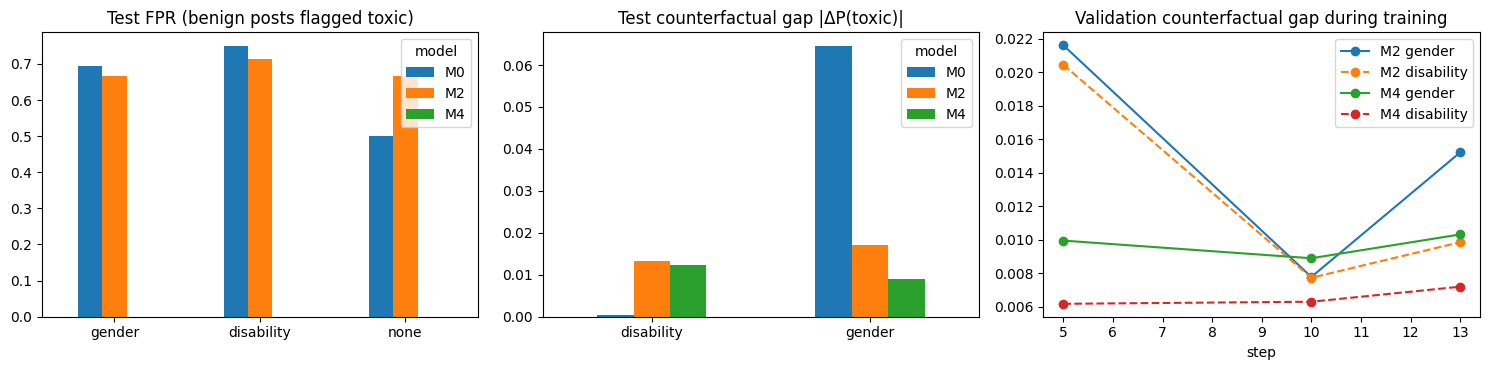

Takeaway (gender): the raw counterfactual gap is M0 0.0646, M2 0.0170, M4 0.0089; benign posts mentioning gender are flagged at M0 69.4%, M2 66.7%, M4 0.0%.
Takeaway (disability): the raw counterfactual gap is M0 0.0003, M2 0.0132, M4 0.0124; benign posts mentioning disability are flagged at M0 75.0%, M2 71.4%, M4 0.0%.


In [5]:
import json
import matplotlib.pyplot as plt

runs = {v: Path(out_dir_for(v)) for v in ("M2", "M4") if (Path(out_dir_for(v)) / "metrics.csv").exists()}
if not runs:
    raise FileNotFoundError("No trained model found yet: run section 4 first.")
metrics = pd.concat([pd.read_csv(d / "metrics.csv") for d in runs.values()]).drop_duplicates(["model", "split", "group"])
cfgap = pd.concat([pd.read_csv(d / "counterfactual.csv") for d in runs.values()
                   if (d / "counterfactual.csv").exists()]).drop_duplicates(["model", "split", "axis"])
summaries = {v: json.load(open(d / "training_summary.json")) for v, d in runs.items()}
order = [m for m in ("M0", "M2", "M4") if m in set(metrics["model"])]
comparison = Path(PROJECT_DIR) / ("comparison_quicktest" if QUICK_TEST else "comparison")
comparison.mkdir(exist_ok=True)
metrics.to_csv(comparison / "metrics_M0_M2_M4.csv", index=False)
cfgap.to_csv(comparison / "counterfactual_M0_M2_M4.csv", index=False)

for v, s in summaries.items():
    print(f"{v}: {s['method']} fine-tuning of {s['base_model']}" + (" + counterfactual loss" if s.get("counterfactual") else "")
          + f", {s['optimizer_steps']} steps in {s['train_minutes']} min on {s['environment']['gpu']}, "
          f"best val loss {s['best_val_loss']:.4f}")

groups = ["overall", "mentions=gender", "mentions=disability", "mentions=none"]
test = metrics[(metrics["split"] == "test") & metrics["group"].isin(groups)]
table = test.pivot(index="group", columns="model", values=["accuracy", "macro_f1", "auroc", "fpr", "fnr"]).reindex(groups)
print("\n=== Test error rates ===")
display(table.reindex(columns=order, level=1).round(3))
gap_test = cfgap[cfgap["split"] == "test"].pivot(index="axis", columns="model", values=["gap", "gap_benign", "direction", "flip_rate"])
print("=== Test counterfactual gap (raw) ===")
display(gap_test.reindex(columns=order, level=1).round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
fpr = test[test["group"] != "overall"].pivot(index="group", columns="model", values="fpr").reindex(groups[1:])[order]
fpr.index = [g.replace("mentions=", "") for g in fpr.index]
fpr.plot.bar(ax=axes[0], rot=0); axes[0].set_title("Test FPR (benign posts flagged toxic)"); axes[0].set_xlabel("")
gap = cfgap[cfgap["split"] == "test"].pivot(index="axis", columns="model", values="gap")[order]
gap.plot.bar(ax=axes[1], rot=0); axes[1].set_title("Test counterfactual gap |ΔP(toxic)|"); axes[1].set_xlabel("")
for v, s in summaries.items():
    curve = s.get("val_counterfactual_gap_curve") or []
    for axis, style in (("gender", "-"), ("disability", "--")):
        pts = [(c["step"], c[axis]["gap"]) for c in curve if axis in c]
        if pts:
            axes[2].plot(*zip(*pts), style, marker="o", label=f"{v} {axis}")
axes[2].set_title("Validation counterfactual gap during training"); axes[2].set_xlabel("step"); axes[2].legend()
fig.tight_layout()
fig.savefig(comparison / "M0_M2_M4.png", dpi=200)
plt.show()

def val(df, row, col):
    try:
        return df.loc[row, col]
    except KeyError:
        return float("nan")
for axis in ("gender", "disability"):
    print(f"Takeaway ({axis}): the raw counterfactual gap is " + ", ".join(
        f"{m} {val(gap, axis, m):.4f}" for m in order) + "; benign posts mentioning " + axis + " are flagged at "
        + ", ".join(f"{m} {val(fpr, axis, m):.1%}" for m in order) + ".")

## 6. Upload to Hugging Face (optional)

`m2/` and `m4/` are complete Hugging Face model repos: the weights, tokenizer, `README.md` (a model card with
how to use the model, how it was trained, its error rates and counterfactual gaps vs M0), the prompt
(`m2_prompt.yaml`), `metrics.csv`, `counterfactual.csv` and `training_summary.json`.

1. On huggingface.co → Settings → Access Tokens, create a token with **write** access. Add it in Colab
   as a secret named `HF_TOKEN` (key icon in the left bar), allow notebook access, then re-run the setup
   cell.
2. Set the repo ids below (your username or an organisation you can write to).
3. Run the cell. Repos are created **private**; make them public on their Hub pages when the team agrees.
   Check the data licences in the model card first: ETHOS is GPL-3.0.

Per-post prediction files stay on Drive. Quick-test models are never uploaded.

In [6]:
HF_REPO_IDS = {"M2": None, "M4": None}   # e.g. {"M2": "your-username/kqv-m2-qwen3-4b", "M4": "your-username/kqv-m4-qwen3-4b"}
PRIVATE = True

wanted = {v: r for v, r in HF_REPO_IDS.items() if r}
if wanted:
    from huggingface_hub import HfApi
    if QUICK_TEST:
        raise RuntimeError("These are quick-test models. Run the full training (QUICK_TEST = False) first.")
    token = os.environ.get("HF_TOKEN")
    if not token:
        raise RuntimeError("No HF_TOKEN: add a Hugging Face token with write access as a Colab secret named "
                           "HF_TOKEN, re-run the setup cell, then this one.")
    api = HfApi(token=token)
    for variant, repo_id in wanted.items():
        folder = Path(out_dir_for(variant))
        if not (folder / "training_summary.json").exists():
            print(f"{variant}: not trained yet, skipped")
            continue
        readme = folder / "README.md"
        readme.write_text(readme.read_text(encoding="utf-8").replace("<this repo id>", repo_id), encoding="utf-8")
        url = api.create_repo(repo_id, private=PRIVATE, exist_ok=True)
        api.upload_folder(folder_path=str(folder), repo_id=repo_id, commit_message=f"Upload {variant}",
                          ignore_patterns=["predictions_*.csv", "checkpoints/**", "lora_adapter/**"])
        print(f"{variant}: uploaded {folder} to {url} ({'private' if PRIVATE else 'public'})")
else:
    print("Set HF_REPO_IDS to upload M2 and/or M4 to the Hugging Face Hub.")

Set HF_REPO_IDS to upload M2 and/or M4 to the Hugging Face Hub.


## 7. Use the models in the bias framework

All models are LLMs, so in `bias_study.ipynb` they use `type="hf-causal-lm"`. M0, M2 and M4 use the prompt
they were trained with (`m2_prompt.yaml`, saved in both folders). M1 and M3 use a few-shot prompt with the
**same instruction, system message and No/Yes options**, plus examples, such as the framework's `llm` prompt:

```python
from biascompare import ModelSpec, load_prompts
FOLDER = "/content/drive/MyDrive/<your folder>"   # or Hub repo ids from section 6
base = load_prompts(f"{FOLDER}/m2/m2_prompt.yaml")["instruction"]   # from the Hub: hf_hub_download(repo, "m2_prompt.yaml")
few_shot = load_prompts("data/sample_prompts.yaml")["llm"]           # the team's few-shot prompt
s = {"dtype": "bfloat16"}
MODELS = [ModelSpec("Qwen/Qwen3-4B", type="hf-causal-lm", id="M0", prompt=base, settings=s),
          ModelSpec("Qwen/Qwen3-4B", type="hf-causal-lm", id="M1", prompt=few_shot, settings=s),
          ModelSpec(f"{FOLDER}/m2",  type="hf-causal-lm", id="M2", prompt=base, settings=s),
          ModelSpec(f"{FOLDER}/m2",  type="hf-causal-lm", id="M3", prompt=few_shot, settings=s),
          ModelSpec(f"{FOLDER}/m4",  type="hf-causal-lm", id="M4", prompt=base, settings=s)]
```

M4 vs M2 in the framework's pairwise comparisons is the effect of the counterfactual loss, measured with the
baseline-controlled Δ on the human-verified test swaps, which M4 never saw in training.